In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

sns.set_style("whitegrid")

In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
# Dataset information
print(df.shape)

df.info()

# Statistical summary
display(df.describe())

# Missing values
print(df.isnull().sum())

# Class distribution
print(df["species"].value_counts())

(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


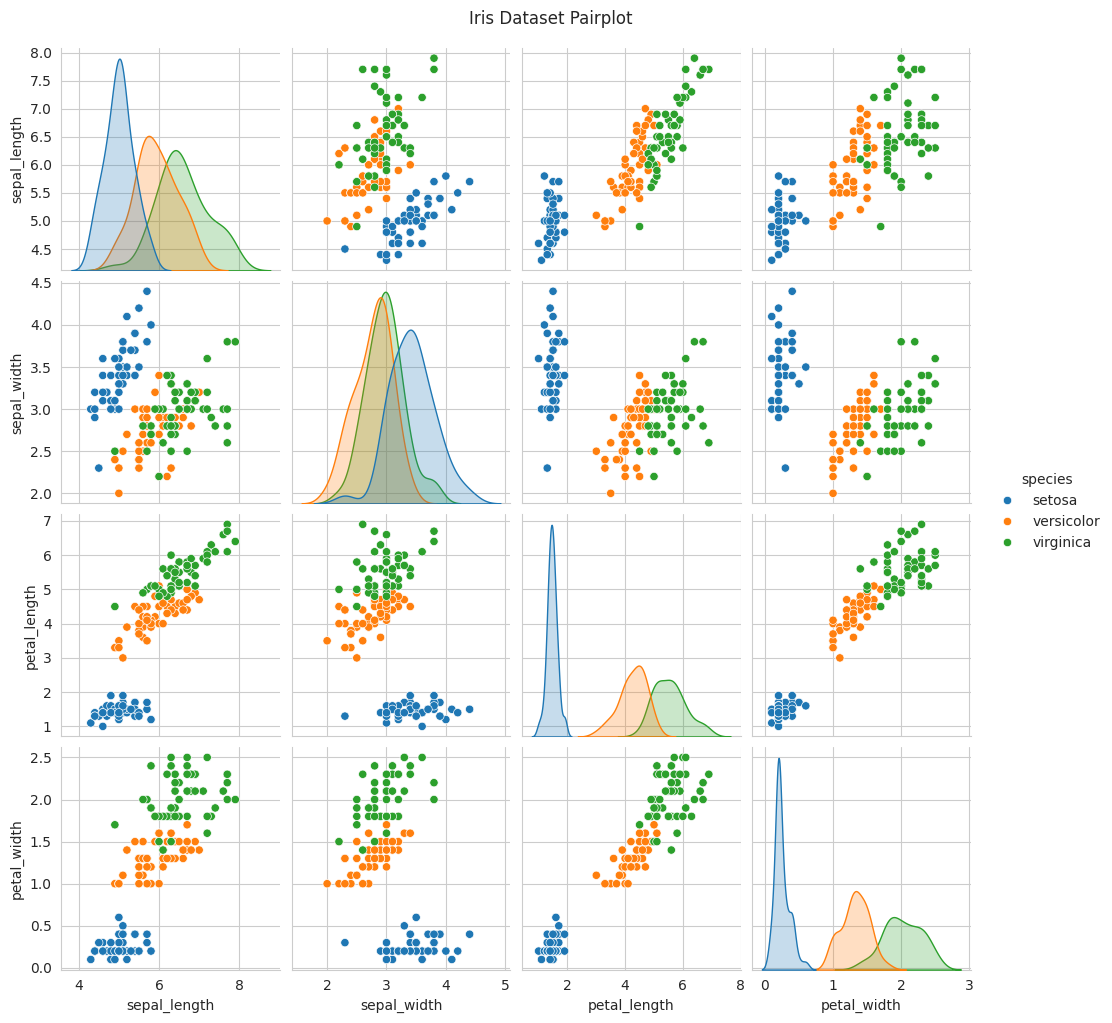

In [ ]:
sns.pairplot(df, hue="species")

plt.suptitle("Iris Dataset Pairplot", y=1.02)

plt.show()

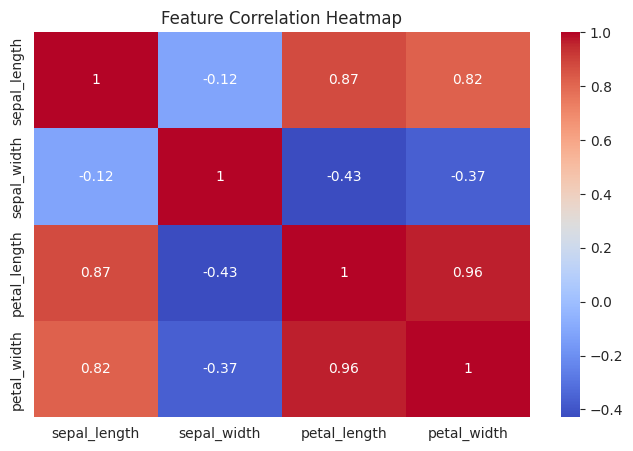

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()

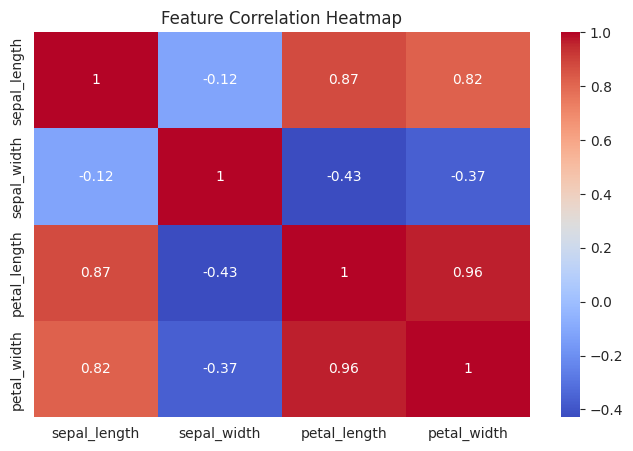

In [ ]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")

plt.show()

In [ ]:
X = df.drop("species", axis=1)

y = df["species"]

print("Features:")
display(X.head())

print("Target:")
display(y.head())

Features:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Target:


,species
0,setosa
1,setosa
2,setosa
3,setosa
4,setosa


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

log_predictions = log_model.predict(X_test_scaled)

In [ ]:
tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

In [ ]:
models = {
    "Logistic Regression": log_predictions,
    "Decision Tree": tree_predictions
}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, average="macro"
    )

    recall = recall_score(
        y_test, predictions, average="macro"
    )

    f1 = f1_score(
        y_test, predictions, average="macro"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


In [ ]:
print("Logistic Regression Report")

print(
    classification_report(
        y_test,
        log_predictions
    )
)

print("Decision Tree Report")

print(
    classification_report(
        y_test,
        tree_predictions
    )
)

Logistic Regression Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



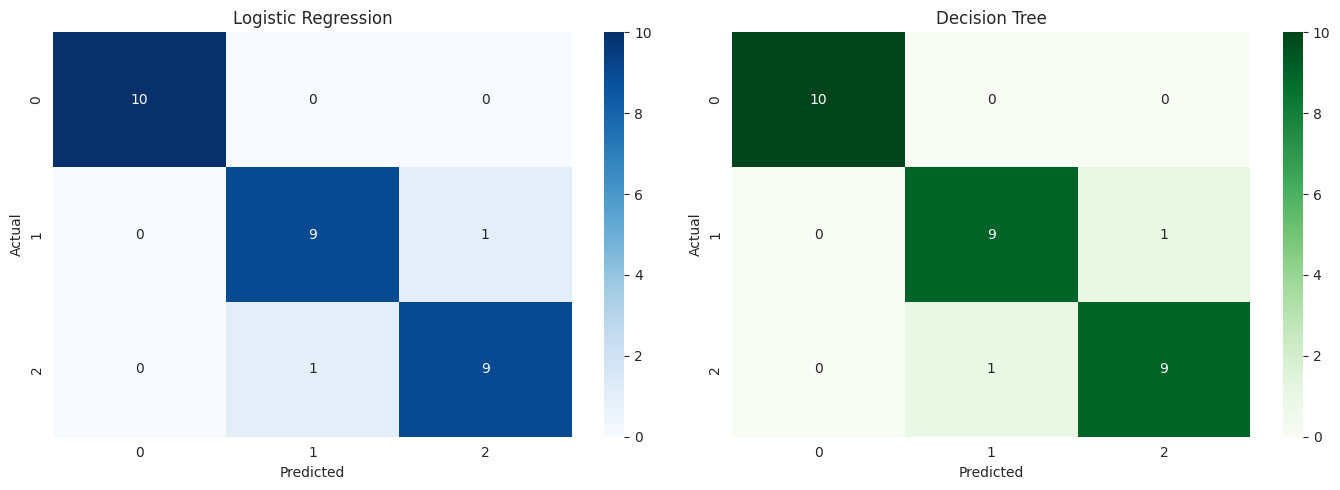

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
cm1 = confusion_matrix(
    y_test,
    log_predictions
)

sns.heatmap(
    cm1,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Decision Tree
cm2 = confusion_matrix(
    y_test,
    tree_predictions
)

sns.heatmap(
    cm2,
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()

plt.show()

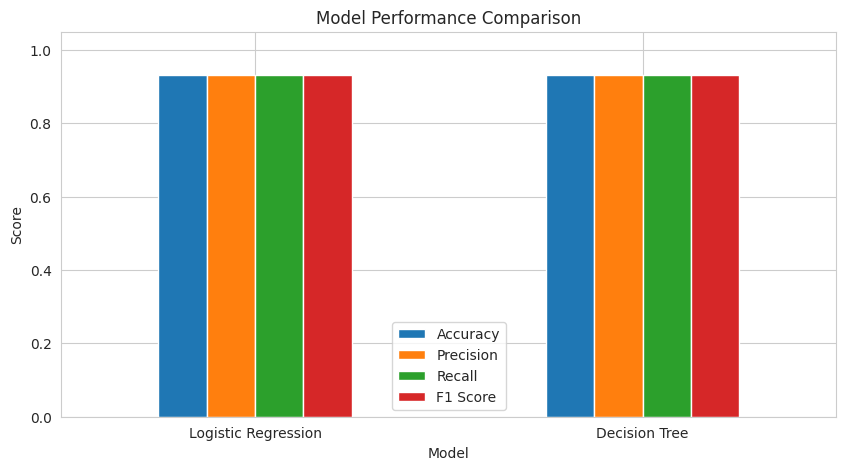

In [ ]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05)
)

plt.title("Model Performance Comparison")

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.show()

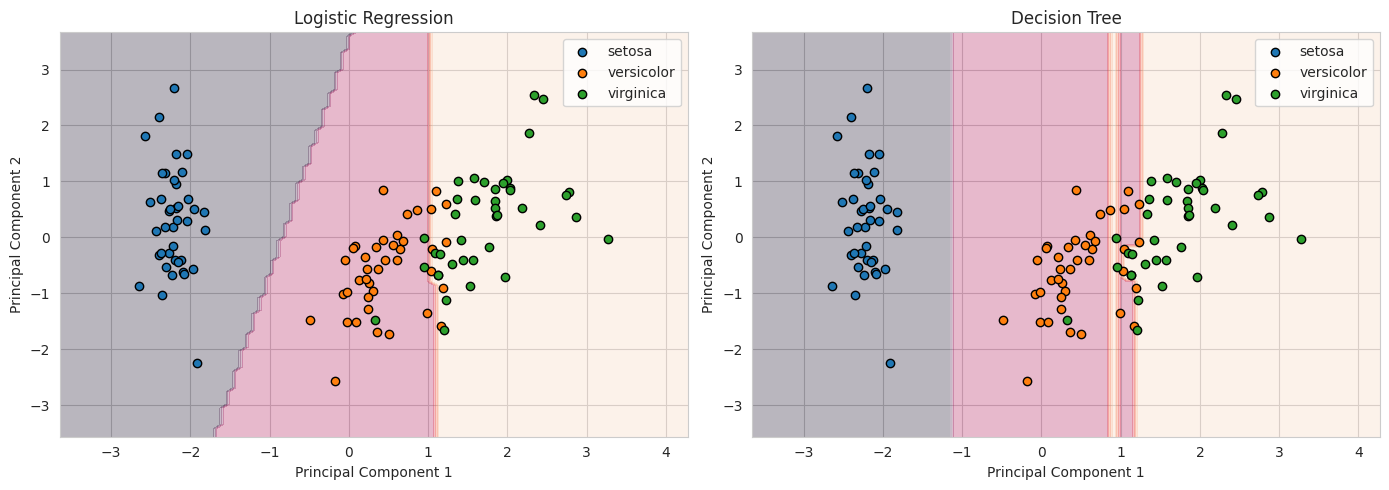

In [ ]:
from sklearn.decomposition import PCA
from sklearn.inspection import DecisionBoundaryDisplay

# Scale and reduce dimensions
pca = PCA(n_components=2)

X_train_2d = pca.fit_transform(X_train_scaled)

# Train 2D visualization models
models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models_2d.items()):

    model.fit(X_train_2d, y_train)

    DecisionBoundaryDisplay.from_estimator(
        model,
        X_train_2d,
        response_method="predict",
        alpha=0.3,
        ax=ax
    )

    for species in sorted(y_train.unique()):
        mask = y_train.to_numpy() == species

        ax.scatter(
            X_train_2d[mask, 0],
            X_train_2d[mask, 1],
            label=species,
            edgecolor="black"
        )

    ax.set_title(name)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
best_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"])
print("F1 Score:", best_model["F1 Score"])

Best Model: Logistic Regression
Accuracy: 0.9333333333333333
F1 Score: 0.9333333333333332
